# Innovación – Buscador semántico de noticias

**Idea:** recuperar las noticias del dataset más parecidas **en significado** a un texto consultado, aunque no compartan palabras exactas.

**Método**

1. Cada noticia (titular + bajada) se convierte en un **embedding**: un vector de 384 números generado por `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, un modelo entrenado para que textos con significado parecido tengan vectores cercanos (funciona bien en español).
2. Los vectores se **normalizan** (largo 1), así la **similitud coseno** entre dos noticias es simplemente su producto punto: 1 = mismo significado, 0 = sin relación.
3. Ante una consulta, se calcula su embedding y se devuelven las noticias con mayor similitud coseno.
4. Los embeddings se guardan en `datos/embeddings.npy` (< 1 MB) para que el dashboard no tenga que recalcularlos.

In [1]:
import time
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from sentence_transformers import SentenceTransformer

pio.renderers.default = "plotly_mimetype+png"
pio.templates.default = "plotly_white"
pd.set_option("display.max_colwidth", 110)

EMB_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
df = pd.read_csv("datos/noticias.csv").fillna({"bajada": ""})
textos = (df["titular"] + ". " + df["bajada"]).tolist()

modelo = SentenceTransformer(EMB_MODEL)
t0 = time.perf_counter()
emb = modelo.encode(textos, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
print(f"Embeddings: {emb.shape} en {time.perf_counter() - t0:.1f} s")

np.save("datos/embeddings.npy", emb.astype(np.float32))
print("Guardado datos/embeddings.npy")

W1018 20:18:39.004000 34472 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings: (384, 384) en 1.1 s
Guardado datos/embeddings.npy


## Función de búsqueda

In [2]:
def buscar(consulta, k=5):
    q = modelo.encode([consulta], normalize_embeddings=True)[0]
    sim = emb @ q                        # similitud coseno (vectores normalizados)
    top = np.argsort(-sim)[:k]
    return df.iloc[top][["titular", "etiqueta"]].assign(similitud=sim[top].round(3))

for consulta in ["subida del precio del dólar",
                 "la selección peruana en las eliminatorias",
                 "riesgos de la inteligencia artificial",
                 "enfrentamiento entre el Congreso y el Ejecutivo"]:
    print(f"\n🔎 {consulta}")
    display(buscar(consulta))


🔎 subida del precio del dólar


,titular,etiqueta,similitud
166,"El dólar abre al alza en S/3,44 tras inflación en Estados Unidos mayor a la esperada",economia,0.769
139,"El dólar abre al alza en S/3,44, pero retrocede ante mayor oferta local",economia,0.735
161,"El dólar cierra al alza en S/3,43 tras inflación mayor a la esperada en Estados Unidos",economia,0.664
107,"El dólar cierra al alza en S/3,43 pese al retroceso de la divisa estadounidense",economia,0.656
182,"El dólar abre en S/3,44 ante retroceso de la divisa estadounidense a nivel global",economia,0.655



🔎 la selección peruana en las eliminatorias


,titular,etiqueta,similitud
72,Los bastiones que dieron la espalda a Juntos por el Perú en las elecciones regionales: ¿los motivos de la ...,politica,0.689
286,¡Impresionante! Perú conquistó catorce medallas en el ALAS Global Tours de Puerto Rico,deportes,0.643
192,"HOY, Alianza Lima vs Rebaza Acosta EN VIVO: horario y dónde ver la Liga Peruana de Vóley",deportes,0.637
171,La gloria gastronómica que debemos multiplicar,economia,0.632
215,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Arge...",deportes,0.630



🔎 riesgos de la inteligencia artificial


,titular,etiqueta,similitud
332,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas,ciencia_tecnologia,0.770
326,Bill Gates: el verdadero peligro de la IA es “que personas malintencionadas la utilicen”,ciencia_tecnologia,0.714
344,Anthropic prohíbe el comportamiento “cruel” hacia su inteligencia artificial Claude,ciencia_tecnologia,0.688
170,La evolución de la confianza en los pagos,economia,0.661
375,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",ciencia_tecnologia,0.660



🔎 enfrentamiento entre el Congreso y el Ejecutivo


,titular,etiqueta,similitud
56,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en grupos del Congreso,politica,0.677
18,Ausencia de senadores de izquierda y aliados frustra debate y votación de facultades: los entretelones de ...,politica,0.630
40,Juan Sheput: “El Congreso ha apostado por la coyuntura y no por las reformas de fondo” | Entrevista,politica,0.621
9,Facultades legislativas: Senado sigue sin alcanzar consenso y debate continúa entrampado,politica,0.618
7,Jorge Nieto dice que se reunió con el Ejecutivo: “Aprobemos los 20 puntos y hágannos llegar como proyecto ...,politica,0.606


**Lectura:** tres de las cuatro consultas funcionan muy bien:

- *"riesgos de la inteligencia artificial"* recupera notas como *"Bill Gates: el verdadero peligro de la IA es que personas malintencionadas la utilicen"*, que no contiene la palabra "riesgos": el buscador encuentra el **significado** (riesgo ≈ peligro), no solo palabras exactas.
- *"enfrentamiento entre el Congreso y el Ejecutivo"* devuelve 5 notas de política sobre el debate de facultades legislativas.
- *"subida del precio del dólar"* devuelve 5 notas de tipo de cambio "al alza".

La consulta *"la selección peruana en las eliminatorias"* **falla**: el primer resultado es de política y los demás solo comparten la idea de "Perú" o de deporte. La razón es que **en los 13 días recolectados no hubo noticias de la selección ni de Eliminatorias**. El buscador solo puede recuperar lo que existe en el dataset y devuelve lo "menos lejano", aunque no sea relevante. Esto muestra una limitación: convendría fijar un umbral mínimo de similitud o avisar cuando ningún resultado sea realmente parecido.

## ¿Los embeddings separan las categorías?

Como validación, se compara la similitud media **dentro** de cada categoría frente a la similitud **entre** categorías distintas.

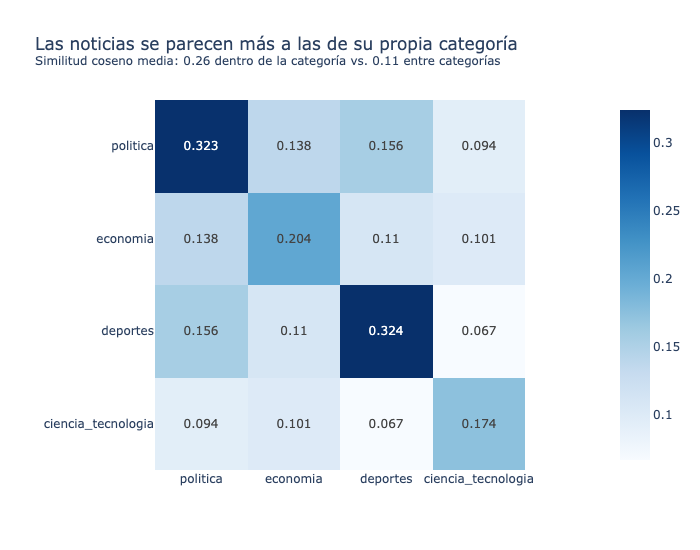

In [3]:
cats = ["politica", "economia", "deportes", "ciencia_tecnologia"]
S = emb @ emb.T
mat = pd.DataFrame(index=cats, columns=cats, dtype=float)
for a in cats:
    for b in cats:
        ia, ib = np.where(df["etiqueta"] == a)[0], np.where(df["etiqueta"] == b)[0]
        bloque = S[np.ix_(ia, ib)]
        mat.loc[a, b] = bloque[~np.eye(len(ia), dtype=bool)].mean() if a == b else bloque.mean()

dentro = np.diag(mat.values).mean()
fuera = mat.values[~np.eye(4, dtype=bool)].mean()
fig = px.imshow(mat.round(3), text_auto=True, color_continuous_scale="Blues",
                title=(f"Las noticias se parecen más a las de su propia categoría<br>"
                       f"<sup>Similitud coseno media: {dentro:.2f} dentro de la categoría vs. {fuera:.2f} entre categorías</sup>"))
fig.update_layout(width=700, height=550, xaxis_title="", yaxis_title="")
fig.show()

## Conclusión

El buscador semántico permite explorar el dataset por significado y está integrado en el dashboard (`app.py`, sección **🔎 Buscador semántico**).

La matriz confirma que, en promedio, cada noticia se parece más a las de su propia categoría (0.26) que a las de otras (0.11). El dato más interesante es la **diagonal**: `politica` y `deportes` son muy homogéneas (≈ 0.32), mientras que **`ciencia_tecnologia` es la menos homogénea (0.17)**. Sus noticias cubren temas muy distintos entre sí (inteligencia artificial, videojuegos, ecología, negocios de empresas tecnológicas), y esa dispersión es coherente con que haya sido la categoría con peor F1 del clasificador (0.75).